# Notebook 6 - Product recommendation engine

> **Mentor briefing** - the seven questions we answer for every phase.

| Question | Answer |
|---|---|
| **1. What are we doing?** | Build and compare four recommenders: popularity, collaborative filtering, content-based and a hybrid, and evaluate them without peeking at the future. |
| **2. Why?** | Recommendations raise basket size and bring customers back; a poor one just shows best-sellers to everyone. |
| **3. Real-world problem it solves** | 'Customers who bought this also bought ...' and 'more like this' on the product page, in e-mails and in the basket. |
| **4. What does the code do?** | Builds a customer x product matrix, item-item cosine similarity, TF-IDF text vectors, blends them with weights 0.6/0.3/0.1 after min-max normalisation, evaluates on a later time period. |
| **5. Expected output** | A top-5 list with reasons, and a metrics table. Expect LOW absolute numbers - predicting *new* products is hard - and a hybrid that beats the baselines. |
| **6. What can go wrong?** | Recommending what the customer already owns; evaluating on data from before the training cut-off; one popular product dominating; cold start; best-seller bias. |
| **7. How do professionals approach this?** | They evaluate offline with time splits, then confirm with an online A/B test, and watch coverage and popularity bias - not just precision. |


## The four recommenders

| Recommender | How it decides | Strength | Weakness |
|---|---|---|---|
| **Popularity** | most orders overall | works for everyone, strong baseline | not personal; recommends the same items to all |
| **Collaborative filtering (item-based)** | products bought by *the same customers* are similar (cosine similarity of customer columns) | finds non-obvious links; no text needed | needs history; favours popular items; cold start |
| **Content-based** | products with *similar descriptions* (TF-IDF + cosine) | works for rarely-sold products | only "more of the same" |
| **Hybrid** | `0.60 x collaborative + 0.30 x content + 0.10 x popularity` | balances the three | weights need tuning on data |

* **Cosine similarity** = the angle between two vectors (1 = same direction, 0 = unrelated). It ignores how *long* the vectors are, so a popular product is not automatically "more similar".
* **TF-IDF** weights a word by how frequent it is in this description (TF) and how *rare* across all descriptions (IDF). "Heart" is informative; "of" is not.
* **Normalise first:** the three scores live on different scales. Each is min-max scaled to 0-1 over the candidate products *before* blending; otherwise the biggest raw numbers silently win.
* **Cold start:** a customer with no history gets the popularity list (flagged `fallback`).

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                      # lets us import our own code from src/
from src.utils.config import get_paths, RANDOM_STATE
paths = get_paths(ROOT)

sns.set_theme(style="whitegrid", context="notebook", palette=["#2563eb", "#0d9488", "#4f46e5", "#eda100", "#eb6834", "#e87ba4"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "figure.figsize": (9, 4.2)})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 140
from src.recommendations.common import build_reco_data
from src.recommendations.hybrid import HybridRecommender, WEIGHTS
from src.recommendations.evaluation import evaluate_recommenders
clean = pd.read_parquet(paths.processed / "cleaned_transactions.parquet")
data = build_reco_data(clean)
print(f"{len(data.customer_ids):,} customers x {data.n_items:,} products")

5,852 customers x 4,723 products


## 1. The customer-product interaction matrix

non-zero cells: 480,967  |  density: 1.74%  (i.e. 98.26% of cells are empty - this is called SPARSITY)


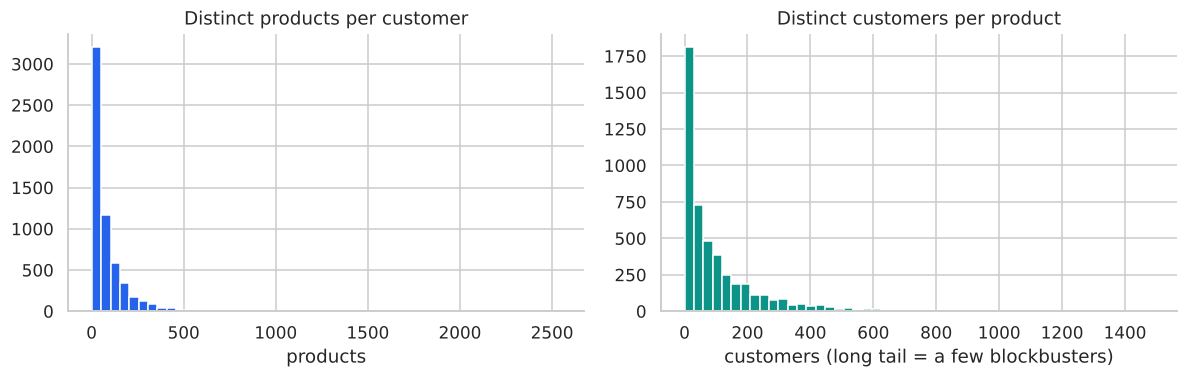

In [2]:
M = data.matrix
density = M.nnz / (M.shape[0] * M.shape[1])
print(f"non-zero cells: {M.nnz:,}  |  density: {density:.2%}  (i.e. {1-density:.2%} of cells are empty - this is called SPARSITY)")
per_cust = np.asarray(M.sum(1)).ravel(); per_item = np.asarray(M.sum(0)).ravel()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(per_cust, bins=50, color="#2563eb"); ax[0].set(title="Distinct products per customer", xlabel="products")
ax[1].hist(per_item, bins=50, color="#0d9488"); ax[1].set(title="Distinct customers per product", xlabel="customers (long tail = a few blockbusters)")
plt.tight_layout(); plt.show()

## 2. Collaborative filtering - 'customers who bought A also bought B'

In [3]:
rec = HybridRecommender.from_transactions(clean)
pop_order = np.argsort(-data.popularity)
anchor = int(pop_order[10])
sim = rec.cf.sim[anchor]
nearest = np.argsort(-sim)[:5]
print("Anchor product :", data.items.at[anchor, "Description"].title())
print("Most similar by CUSTOMER BEHAVIOUR:")
for j in nearest: print(f"   {sim[j]:.2f}  {data.items.at[j, 'Description'].title()}")

Anchor product : Jumbo Storage Bag Suki
Most similar by CUSTOMER BEHAVIOUR:
   0.55  Jumbo Storage Bag Skulls
   0.54  Jumbo Bag Spaceboy Design
   0.53  Jumbo Bag Owls
   0.52  Jumbo Bag Red Retrospot
   0.51  Lunch Bag Suki Design


Expect close relatives (same family or colour variants). Collaborative filtering never read the words - it discovered the family purely from who bought what.

## 3. Content-based filtering - 'more like this'

In [4]:
cb = rec.cb
print("type of the TF-IDF matrix:", type(cb.tfidf).__name__, "shape", cb.tfidf.shape)
from sklearn.metrics.pairwise import cosine_similarity
cs = cosine_similarity(cb.tfidf[anchor], cb.tfidf).ravel(); cs[anchor] = 0
print("\nAnchor product :", data.items.at[anchor, "Description"].title())
print("Most similar by DESCRIPTION TEXT:")
for j in np.argsort(-cs)[:5]: print(f"   {cs[j]:.2f}  {data.items.at[j, 'Description'].title()}")

type of the TF-IDF matrix: csr_matrix shape (4723, 10846)

Anchor product : Jumbo Storage Bag Suki
Most similar by DESCRIPTION TEXT:
   0.67  Jumbo Storage Bag Skulls
   0.41  Lunch Bag Suki Design
   0.40  Charlotte Bag Suki Design
   0.24  Suki Shoulder Bag
   0.21  Jumbo Bag Apples


## 4. Hybrid recommendations for one customer, with explanations

In [5]:
cid = int(data.customer_ids[np.argmax(per_cust)])      # a heavy buyer
print("customer", cid, "has bought", len(data.history[cid]), "different products")
out = rec.recommend(cid, n=5)
display(out[["description", "score", "collaborative", "content", "popularity", "reason"]].round(3))
bought = {data.items.at[i, "StockCode"] for i in data.history[cid]}
assert not set(out.stock_code) & bought; print("none of the recommended products was bought before - OK")

customer 14911 has bought 2546 different products


,description,score,collaborative,content,popularity,reason
0,IVORY HANGING DECORATION HEART,0.76,0.85,0.71,0.36,Customers who bought 'Heart Ivory Trellis Smal...
1,PACK OF 12 LONDON TISSUES,0.76,0.89,0.59,0.43,Customers who bought 'Lunch Box I Love London'...
2,JUMBO STORAGE BAG SKULLS,0.74,0.96,0.33,0.69,Customers who bought 'Jumbo Storage Bag Suki' ...
3,VINTAGE UNION JACK BUNTING,0.73,0.97,0.27,0.68,Customers who bought 'Party Bunting' often buy...
4,SET OF 60 I LOVE LONDON CAKE CASES,0.73,0.77,0.82,0.21,Customers who bought 'Set Of 60 Vintage Leaf C...


none of the recommended products was bought before - OK


In [6]:
print("A brand-new visitor (no history) gets the fallback:")
rec.recommend(customer_id=None, n=3)[["description", "reason", "fallback"]]

A brand-new visitor (no history) gets the fallback:


,description,reason,fallback
0,WHITE HANGING HEART T-LIGHT HOLDER,"No purchase history yet, so we show what is po...",True
1,JUMBO BAG RED RETROSPOT,"No purchase history yet, so we show what is po...",True
2,REGENCY CAKESTAND 3 TIER,"No purchase history yet, so we show what is po...",True


## 5. Time-aware evaluation (no peeking)

1. Pick a **split date** (the last 60 days of data).
2. Fit every recommender **only on transactions before it**.
3. The ground truth for a customer is the set of **new** products they bought *after* the split - products they never bought before. (Re-buying the same item would be too easy and not a "recommendation".)
4. Recommend 5 products and compare.

| Metric | Question it answers |
|---|---|
| **Precision@5** | of the 5 shown, how many were bought? |
| **Recall@5** | of everything they went on to buy, how much did we show? |
| **NDCG@5** | did we put the hits at the *top* of the list? |
| **Coverage** | what share of the catalogue ever gets recommended? |
| **Popularity bias** | do we only recommend best-sellers? (share of recommendations from the top-10% most popular products) |

In [7]:
split = clean["InvoiceDate"].max().normalize() - pd.Timedelta(days=60)
ev = evaluate_recommenders(clean, split)
print("split date:", split.date(), "| evaluation customers:", ev["n_eval_customers"], "| catalogue size at split:", ev["n_train_items"])
tbl = pd.DataFrame(ev["models"]).T
display(tbl.round(4))
saved = json.loads((paths.models / "recommender_eval.json").read_text())
assert saved["models"]["hybrid"] == ev["models"]["hybrid"]; print("matches models/recommender_eval.json")

split date: 2011-10-10 | evaluation customers: 800 | catalogue size at split: 4618


,precision@5,recall@5,ndcg@5,coverage,avg_popularity_percentile,top10pct_item_share
popularity,0.03,0.01,0.03,0.01,1.00,1.00
collaborative,0.06,0.02,0.07,0.07,0.98,0.97
content,0.06,0.03,0.07,0.19,0.75,0.39
hybrid,0.07,0.03,0.07,0.11,0.96,0.91


matches models/recommender_eval.json


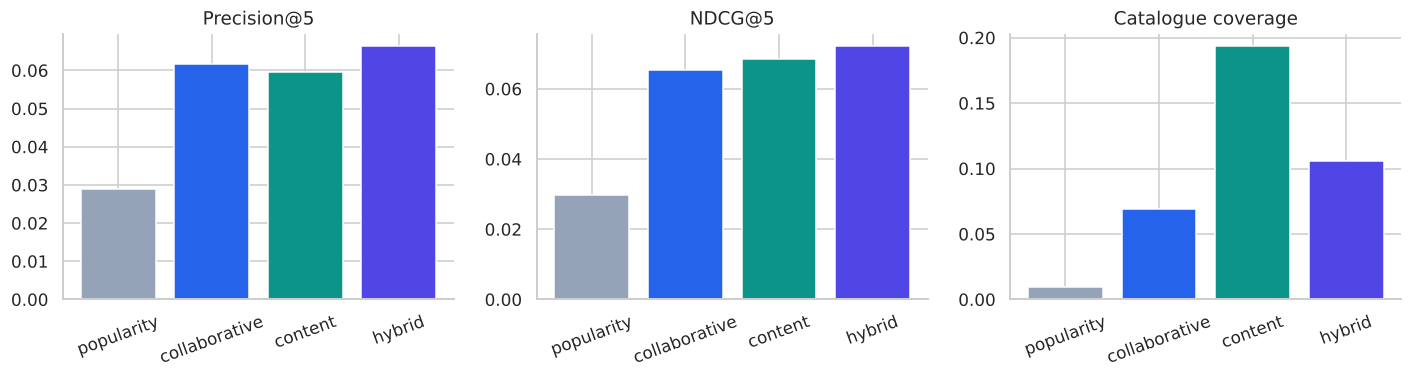

customers' actual new purchases sit at popularity percentile 0.71; recommendations sit at: popularity 1.00, collaborative 0.98, content 0.75, hybrid 0.96


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, col, t in zip(ax, ["precision@5", "ndcg@5", "coverage"], ["Precision@5", "NDCG@5", "Catalogue coverage"]):
    a.bar(tbl.index, tbl[col], color=["#94a3b8", "#2563eb", "#0d9488", "#4f46e5"]); a.set_title(t); a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
print(f"customers' actual new purchases sit at popularity percentile {ev['actual_purchase_popularity_percentile']:.2f};"
      f" recommendations sit at: " + ", ".join(f"{n} {r['avg_popularity_percentile']:.2f}" for n, r in ev['models'].items()))

### How to read these honestly
* Absolute precision is **low** (a few percent). That is normal: with thousands of products and a *new-item* target, even a perfect-taste system rarely hits. What matters is the **ranking**: hybrid and the personalised models beat plain popularity.
* **Popularity bias:** compare the "popularity percentile" of recommendations with that of what customers *actually* bought. If recommendations sit much higher, the system over-promotes best-sellers - good for accuracy, bad for discovery. **Coverage** shows the same story from the catalogue side: popularity recommends a sliver of products; content-based reaches far more.
* The hybrid is a **trade-off** (0.6/0.3/0.1 is given by the project brief, not tuned on this test period - tuning it on the same data we report would be cheating). A production team would tune the weights on a *validation* period and confirm with an A/B test.

## Check yourself
1. Why must the recommender be fitted only on data *before* the split date?
2. Why do we normalise each component before blending?
3. A product has been in the catalogue for one week. Which of the three signals can still recommend it?